# Speed-only baselines, scored with TIMSE on the eval year

Four reference models that use **only** the hourly real-time ACE speed series pulled by
`python -m training.pull_ace_rtsw`. Every model is fitted on the training years only and scored by
`training.evaluate` on the held-out eval year, under the rules in `docs/evaluation.md`.

1. **Models**: what each baseline does.
2. **Official scores**: TIMSE (the ranking metric) and RMSE, through the evaluation harness.
3. **Diagnostics**: error by lead time and by observed speed, and the TIMSE tail curve that explains the ranking.
4. **Findings and summary.**

The same scores can be reproduced without the notebook with `python -m training.run_baselines`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import run_baselines
from training.baselines import ALL
from training.datasets import DATA_DIR, EVAL_END, TRAIN_END, load_eval, load_hourly, load_train
from training.evaluate import HORIZON, forecast_times
from training.metrics import tail_mse_curve

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 1)

## 0. Data and split

The split dates are pinned in `training.datasets`, so the eval year never moves. Missing hours are
left as NaN: they are never fed to a model as targets, and TIMSE skips them.

In [2]:
manifest = json.loads((DATA_DIR / "manifest.json").read_text())
series = load_hourly()
train, held_out = load_train(), load_eval()

pd.DataFrame(
    {
        "start": [train.index[0], held_out.index[0]],
        "end (exclusive)": [TRAIN_END, EVAL_END],
        "hours": [len(train), len(held_out)],
        "% missing": [100 * train.isna().mean(), 100 * held_out.isna().mean()],
        "median km/s": [train.median(), held_out.median()],
        "p99 km/s": [train.quantile(0.99), held_out.quantile(0.99)],
    },
    index=["train", "eval"],
)

,start,end (exclusive),hours,% missing,median km/s,p99 km/s
train,2021-10-20 00:00:00+00:00,2025-10-20 00:00:00+00:00,35064,6.0,421.6,721.0
eval,2025-10-20 00:00:00+00:00,2026-10-20 00:00:00+00:00,8760,1.3,446.2,758.6


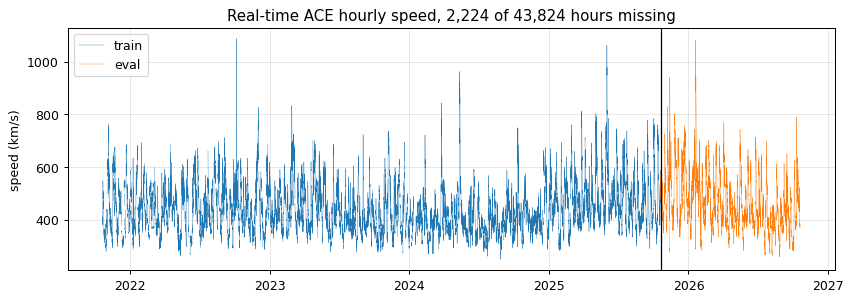

In [3]:
fig, ax = plt.subplots()
ax.plot(train.index, train, lw=0.3, color="tab:blue", label="train")
ax.plot(held_out.index, held_out, lw=0.3, color="tab:orange", label="eval")
ax.axvline(TRAIN_END, color="k", lw=1)
ax.set_ylabel("speed (km/s)")
missing, hours = manifest["missing_hours"], manifest["hours"]
ax.set_title(f"Real-time ACE hourly speed, {missing:,} of {hours:,} hours missing")
ax.legend(loc="upper left");

## 1. Models

All models are in `src/training/baselines.py`. The fitted models learn separate coefficients for
each lead hour k = 1…72, using every hour of the training years as a t0. A training sample is
dropped when its target is missing. Hyper-parameters are fixed and were not tuned on the eval year.

| Model | Forecast for t0 + k h |
|---|---|
| `persistence` | the last observed speed, for every k |
| `climatology_blend` | μ + wₖ·(last − μ). μ is the training mean; wₖ ∈ [0, 1] is fitted by least squares |
| `recurrence_27d` | aₖ + bₖ·last + cₖ·r. r is the mean speed within ±3 h of t0 + k − 27 days (one solar rotation); fitted by least squares |
| `autoregressive_48h` | Ridge regression (α = 1) on the last 48 hourly speeds |

**Missing inputs.** If no speed has been observed, `last` becomes μ. A recurrence window with no
data uses μ. A missing lag hour is replaced with `last`. These substitutions only affect the model
inputs; the stored data stays un-imputed.

## 2. Official scores

`run_baselines.run()` passes each model through `training.evaluate.evaluate`. The harness fits the
model on the training years, forecasts every 6-hourly t0 in the eval year from data observed by t0,
and pools all forecasts into one TIMSE. Lower is better.

In [4]:
scores = run_baselines.run()
scores

  persistence          TIMSE 8.13e+07  RMSE 110.0


  climatology_blend    TIMSE 9.855e+07  RMSE 91.9


  recurrence_27d       TIMSE 8.397e+07  RMSE 84.4


  autoregressive_48h   TIMSE 1.043e+08  RMSE 91.4


,model,timse,rmse,n_forecasts,n_scored,n_missing_actual,seconds
0,persistence,8.1e+07,110.0,1448,102912,1344,0.4
1,recurrence_27d,8.4e+07,84.4,1448,102912,1344,1.1
2,climatology_blend,9.9e+07,91.9,1448,102912,1344,0.5
3,autoregressive_48h,1.0e+08,91.4,1448,102912,1344,6.2


## 3. Diagnostics

The harness only returns scores. To look inside them, the cell below repeats the same protocol and
keeps the forecasts: fit on `load_train()` only, then predict every eval t0 from the hours before it.

In [5]:
t0s = forecast_times()
positions = series.index.get_indexer(t0s)
actual = np.stack([series.iloc[p + 1 : p + 1 + HORIZON].to_numpy() for p in positions])

forecasts = {}
for name, cls in ALL.items():
    model = cls().fit(load_train())
    forecasts[name] = np.stack(
        [model.predict(series.iloc[:p], t0) for p, t0 in zip(positions, t0s, strict=True)]
    )

print(f"{len(t0s)} forecasts x {HORIZON} leads; {np.isnan(actual).sum()} actuals missing")

1448 forecasts x 72 leads; 1344 actuals missing


### 3.1 Error by lead time

All models start at about 22 km/s at 1 h. Persistence degrades fastest, and recurrence holds up
best at long leads.

lead (h),1,6,24,48,72
persistence,21.7,47.7,94.8,127.7,143.4
climatology_blend,21.6,46.6,86.0,105.3,110.6
recurrence_27d,21.5,46.1,81.7,95.4,98.3
autoregressive_48h,21.5,46.2,85.0,104.9,110.7


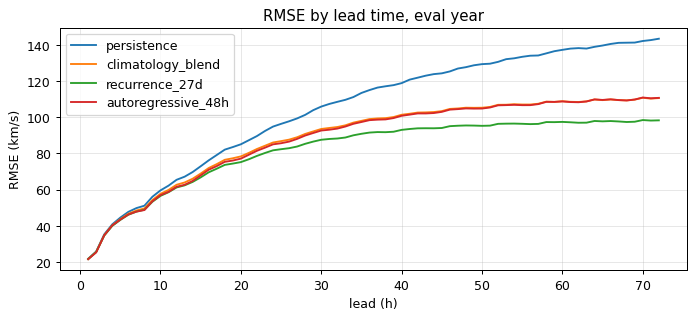

In [6]:
lead_rmse = pd.DataFrame(
    {name: np.sqrt(np.nanmean((f - actual) ** 2, axis=0)) for name, f in forecasts.items()},
    index=pd.RangeIndex(1, HORIZON + 1, name="lead (h)"),
)
ax = lead_rmse.plot(figsize=(9, 3.5))
ax.set_ylabel("RMSE (km/s)")
ax.set_title("RMSE by lead time, eval year")
lead_rmse.loc[[1, 6, 24, 48, 72]].T

### 3.2 Error by observed speed

Bias = forecast − actual. Every model is too high in slow wind and too low in fast wind. The
question for TIMSE is how far each model falls short in fast wind.

In [7]:
bands = [(0, 450), (450, 600), (600, 700), (700, 2000)]
rows = {}
for name, f in forecasts.items():
    row = {}
    for lo, hi in bands:
        sel = (actual >= lo) & (actual < hi)
        err = f[sel] - actual[sel]
        label = f"{lo}-{hi}" if hi < 2000 else f">={lo}"
        row[(label, "bias")] = err.mean()
        row[(label, "rmse")] = np.sqrt((err**2).mean())
    rows[name] = row
by_speed = pd.DataFrame(rows).T
by_speed.columns = pd.MultiIndex.from_tuples(by_speed.columns)
n_band = {
    (f"{lo}-{hi}" if hi < 2000 else f">={lo}"): int(((actual >= lo) & (actual < hi)).sum())
    for lo, hi in bands
}
print("points per band:", n_band)
by_speed

points per band: {'0-450': 53190, '450-600': 36282, '600-700': 10764, '>=700': 2676}


0-450       450-600        600-700         >=700       
                    bias  rmse    bias   rmse    bias   rmse   bias   rmse
persistence         37.0  81.0    -9.2  108.1  -100.7  161.9 -200.8  266.3
climatology_blend   39.6  59.5   -38.1   71.6  -136.9  162.0 -241.5  281.8
recurrence_27d      38.5  60.2   -25.7   61.9  -116.7  142.7 -218.2  260.3
autoregressive_48h  37.2  57.0   -38.6   71.7  -134.8  161.6 -240.4  286.3

### 3.3 Why the TIMSE ranking differs from RMSE

TIMSE = Σⱼ (v*ⱼ₊₁ − v*ⱼ)·Mⱼ, where Mⱼ is the mean squared error over the hours with an observed speed
≥ v*ⱼ. In other words, TIMSE is the area under the tail-MSE curve M(v) plotted against the threshold v.
Each km/s of threshold counts equally, whether a threshold has many hours above it or only a few. The
long, sparsely populated fast tail (600 → 900+ km/s) therefore contributes a large share of the area.
`training.metrics.tail_mse_curve` returns exactly the curve that `timse` integrates.

share of scored points: {'>= 600': '13.1%', '>= 800': '0.5%'}


,thresholds 0-600,thresholds 600-800,thresholds 800-2000,TIMSE
persistence,6.44e+06,1.63e+07,5.86e+07,8.13e+07
climatology_blend,5.3e+06,1.82e+07,7.5e+07,9.85e+07
recurrence_27d,4.26e+06,1.59e+07,6.39e+07,8.4e+07
autoregressive_48h,5.33e+06,1.9e+07,8e+07,1.04e+08


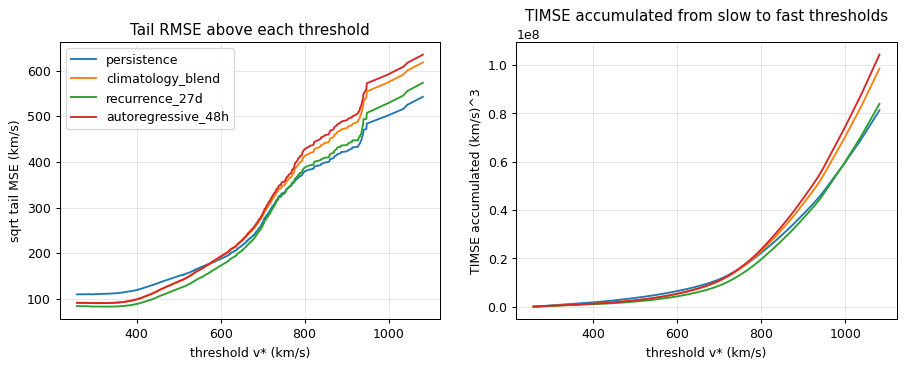

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split = {}
for name, f in forecasts.items():
    v, m = tail_mse_curve(actual, f)  # the same curve training.metrics.timse integrates
    contrib = np.diff(v) * m[:-1]  # TIMSE contribution of each threshold gap
    axes[0].plot(v, np.sqrt(m), label=name)
    axes[1].plot(v[1:], np.cumsum(contrib), label=name)
    split[name] = {
        f"thresholds {lo}-{hi}": contrib[(v[:-1] >= lo) & (v[:-1] < hi)].sum()
        for lo, hi in [(0, 600), (600, 800), (800, 2000)]
    }
    split[name]["TIMSE"] = contrib.sum()
axes[0].set(xlabel="threshold v* (km/s)", ylabel="sqrt tail MSE (km/s)")
axes[0].set_title("Tail RMSE above each threshold")
axes[1].set(xlabel="threshold v* (km/s)", ylabel="TIMSE accumulated (km/s)^3")
axes[1].set_title("TIMSE accumulated from slow to fast thresholds")
axes[0].legend()

observed = actual[np.isfinite(actual)]
print("share of scored points:", {f">= {v}": f"{(observed >= v).mean():.1%}" for v in (600, 800)})
pd.DataFrame(split).T.map("{:.3g}".format)

### 3.4 A fast-stream example

The 48-hour-ahead forecasts around the fastest wind in the eval year. Each point is the forecast made
48 h earlier for that hour.

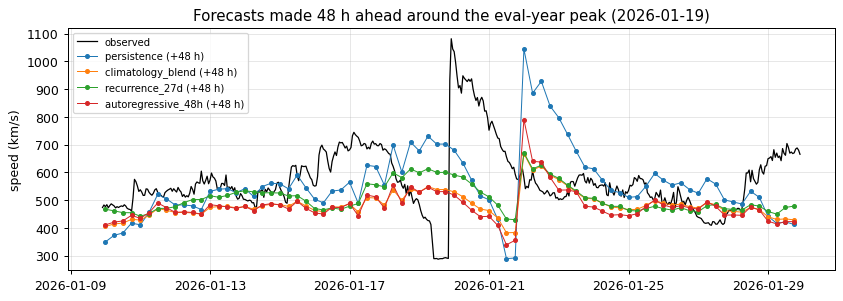

In [9]:
lead = 48
target_times = t0s + pd.Timedelta(hours=lead)
peak = held_out.idxmax()
start, end = peak - pd.Timedelta(days=10), peak + pd.Timedelta(days=10)
window = (target_times >= start) & (target_times <= end)

fig, ax = plt.subplots()
obs = series[start:end]
ax.plot(obs.index, obs, color="k", lw=1, label="observed")
for name, f in forecasts.items():
    label = f"{name} (+{lead} h)"
    ax.plot(target_times[window], f[window, lead - 1], marker=".", lw=0.8, label=label)
ax.set_ylabel("speed (km/s)")
ax.set_title(f"Forecasts made {lead} h ahead around the eval-year peak ({peak:%Y-%m-%d})")
ax.legend(fontsize=8, loc="upper left");

## 4. Findings

Eval year: 2025-10-20 → 2026-10-20. 1,448 forecasts; 102,912 hourly points scored and 1,344 skipped because the actual was missing.

### (i) Ranking
- **Persistence is the TIMSE bar to beat, at 8.13 × 10⁷ (km/s)³.** Recurrence comes next at 8.40 × 10⁷, then climatology blend (9.86 × 10⁷) and autoregressive (10.43 × 10⁷).
- **RMSE ranks the models almost the other way round.** Recurrence is best (84 km/s), and persistence is worst (110 km/s). A model chosen by RMSE would be the wrong choice for this competition.

### (ii) Why
- **TIMSE is decided by a few extreme hours.** Every km/s of threshold counts equally, however few hours lie above it. For persistence:
  - 92% of TIMSE comes from thresholds ≥ 600 km/s (13% of scored points);
  - 72% from thresholds ≥ 800 km/s (0.5% of points);
  - 53% from thresholds ≥ 900 km/s, which covers only **20 hours of the eval year, from two events** (2025-11-13 and 2026-01-19/20).
- **The fitted models are pulled toward the mean.** Least squares makes them under-predict fast wind more than persistence. Above 700 km/s the bias is −218 to −241 km/s for the fitted models and −201 for persistence.
- **Recurrence is better almost everywhere else.** It has the best RMSE at every lead from 6 h on (98 km/s at 72 h, against 143 for persistence). Its accumulated TIMSE stays at or below persistence's up to thresholds of about 950 km/s. Persistence only wins on the thresholds above that, which means on those two events.
- **So the top of the ranking is fragile.** Swap two storms and the order of persistence and recurrence could flip. Treat small TIMSE differences between models with caution.

### (iii) What no speed-only model can do
- **Sudden jumps are invisible to these models.** The fastest event in the eval year jumped from about 300 to 1,080 km/s on 2026-01-19, probably a CME. Every model missed it. Afterwards, persistence over-predicted for days as it repeated the peak.
- **Predicting those jumps needs other inputs.** Examples are coronal-hole and CME information, or solar-wind source-region models. Past speed can't show them coming.
- **Real-time data at extremes needs a check.** The real-time speed dipped to about 290 km/s right before the jump. That may be an instrument artefact during the event. It is still the series the live leaderboard scores against.

## 5. Summary

**Bottom line:** persistence (TIMSE 8.13 × 10⁷) is the score a model must beat. Recurrence is the
most accurate baseline on average and only loses on TIMSE because of the two fastest events of the
eval year.

| Area | Outcome | What it means for the next model |
|---|---|---|
| **Metric** | 72% of TIMSE comes from 0.5% of hours (thresholds ≥ 800 km/s), and 53% from 20 hours in two events (≥ 900 km/s). | Optimise and select models for the fast tail. Use TIMSE, or a loss weighted like it, rather than plain MSE. Small TIMSE gaps may be noise from a few events. |
| **Shrinkage** | Least-squares models under-predict fast wind by 218–241 km/s above 700 km/s. | Avoid pulling forecasts toward the mean. Train with a tail-weighted loss, or blend in persistence. |
| **Recurrence** | Best RMSE from 6 h on. Level with or ahead of persistence on TIMSE up to thresholds of about 950 km/s. | Keep the 27-day signal. For example, use persistence for short leads and recurrence for long ones, fitted to TIMSE. |
| **Extremes** | CME-like jumps are missed by every speed-only model. | Add solar inputs to see them coming. Speed history alone has a ceiling. |